In [3]:
# SmartStorage EDA

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
DATA_PATH = Path("dataset/retail_store_inventory.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [4]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Unique dates:", df["Date"].nunique())
print("Unique stores:", df["Store ID"].nunique())
print("Unique products:", df["Product ID"].nunique())
print("Unique categories:", df["Category"].nunique())
print("Unique regions:", df["Region"].nunique())
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))


Rows: 73100
Columns: 15
Date range: 2022-01-01 00:00:00 to 2024-01-01 00:00:00
Unique dates: 731
Unique stores: 5
Unique products: 20
Unique categories: 5
Unique regions: 4

Columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

Data types:


,dtype
Date,datetime64[ns]
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Demand Forecast,float64
Price,float64


In [5]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().sum() / len(df) * 100).round(3)
})
display(missing)
print("Duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
Date,0,0.0
Store ID,0,0.0
Product ID,0,0.0
Category,0,0.0
Region,0,0.0
Inventory Level,0,0.0
Units Sold,0,0.0
Units Ordered,0,0.0
Demand Forecast,0,0.0
Price,0,0.0


Duplicate rows: 0


In [6]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()
print("Numerical columns:")
print(numerical_columns)
print("\nCategorical columns:")
print(categorical_columns)
display(df[numerical_columns].describe().T)


Numerical columns:
['Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing']

Categorical columns:
['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


,count,mean,std,min,25%,50%,75%,max
Inventory Level,73100.0,274.469877,129.949514,50.00,162.00,273.000,387.0000,500.00
Units Sold,73100.0,136.464870,108.919406,0.00,49.00,107.000,203.0000,499.00
Units Ordered,73100.0,110.004473,52.277448,20.00,65.00,110.000,155.0000,200.00
Demand Forecast,73100.0,141.494720,109.254076,-9.99,53.67,113.015,208.0525,518.55
Price,73100.0,55.135108,26.021945,10.00,32.65,55.050,77.8600,100.00
Discount,73100.0,10.009508,7.083746,0.00,5.00,10.000,15.0000,20.00
Holiday/Promotion,73100.0,0.497305,0.499996,0.00,0.00,0.000,1.0000,1.00
Competitor Pricing,73100.0,55.146077,26.191408,5.03,32.68,55.010,77.8200,104.94


In [7]:
for col in categorical_columns:
    print(f"\n{col}")
    display(df[col].value_counts().to_frame("Count"))



Store ID


,Count
Store ID,
S001,14620
S002,14620
S003,14620
S004,14620
S005,14620



Product ID


,Count
Product ID,
P0001,3655
P0002,3655
P0003,3655
P0004,3655
P0005,3655
P0006,3655
P0007,3655
P0008,3655
P0009,3655



Category


...

,Count
Region,
East,18349
South,18297
North,18228
West,18226



Weather Condition


,Count
Weather Condition,
Sunny,18290
Rainy,18278
Snowy,18272
Cloudy,18260



Seasonality


,Count
Seasonality,
Spring,18317
Summer,18305
Winter,18285
Autumn,18193


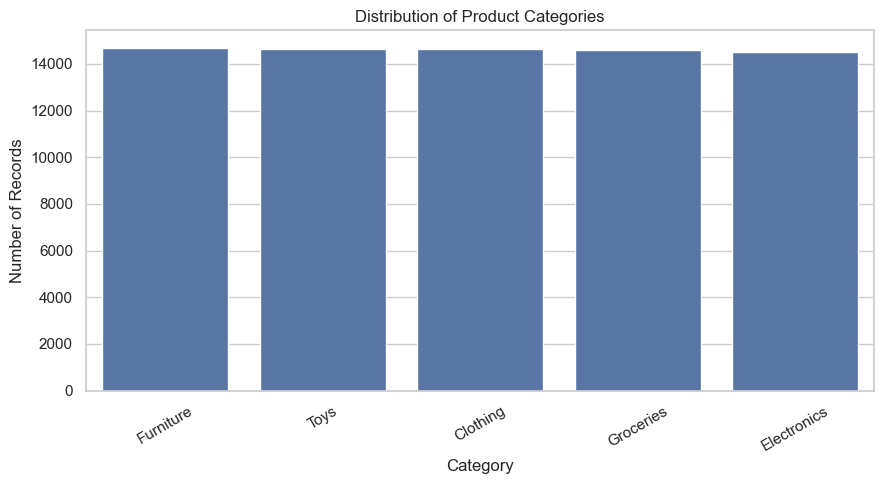

In [8]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Category", order=df["Category"].value_counts().index)
plt.title("Distribution of Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


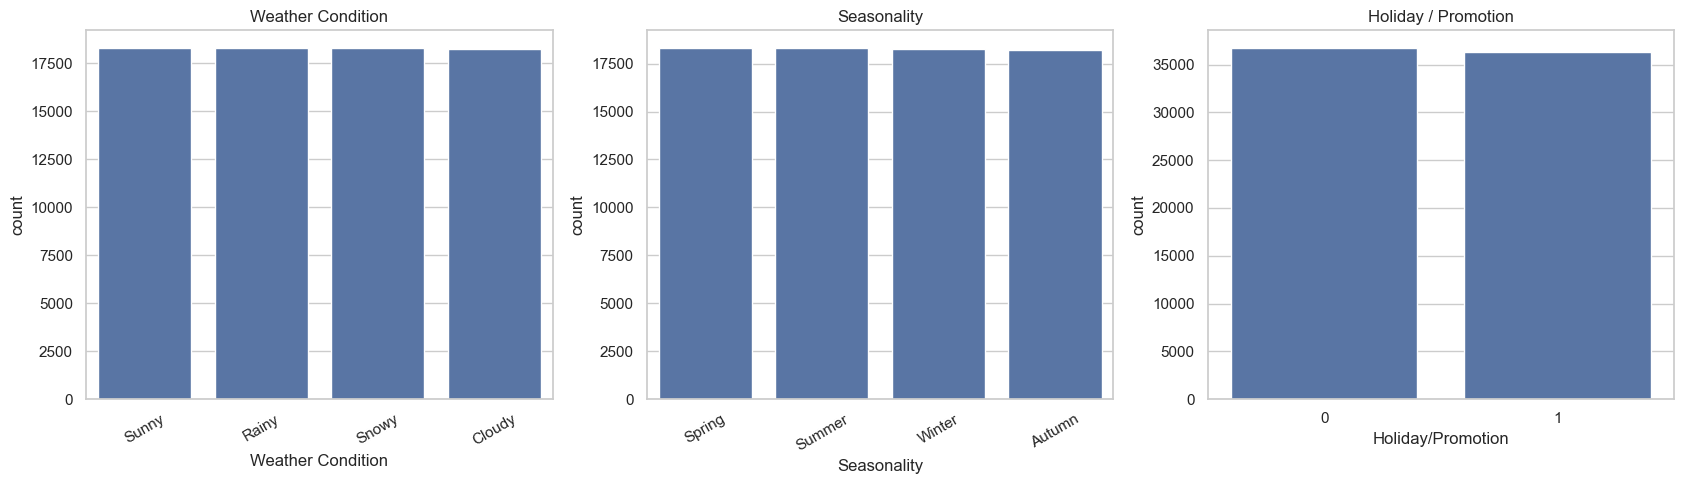

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.countplot(data=df, x="Weather Condition", order=df["Weather Condition"].value_counts().index, ax=axes[0])
axes[0].set_title("Weather Condition")
axes[0].tick_params(axis="x", rotation=30)
sns.countplot(data=df, x="Seasonality", order=df["Seasonality"].value_counts().index, ax=axes[1])
axes[1].set_title("Seasonality")
axes[1].tick_params(axis="x", rotation=30)
sns.countplot(data=df, x="Holiday/Promotion", ax=axes[2])
axes[2].set_title("Holiday / Promotion")
plt.tight_layout()
plt.show()


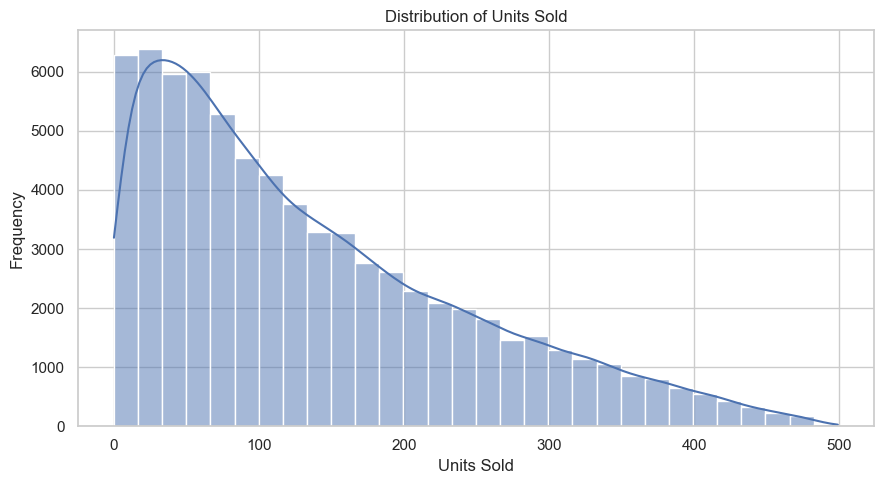

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Units Sold"], bins=30, kde=True)
plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


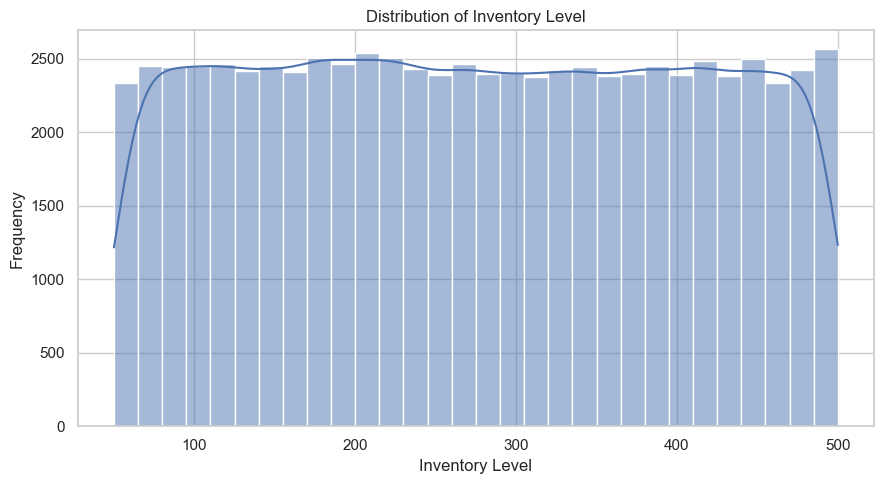

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Inventory Level"], bins=30, kde=True)
plt.title("Distribution of Inventory Level")
plt.xlabel("Inventory Level")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


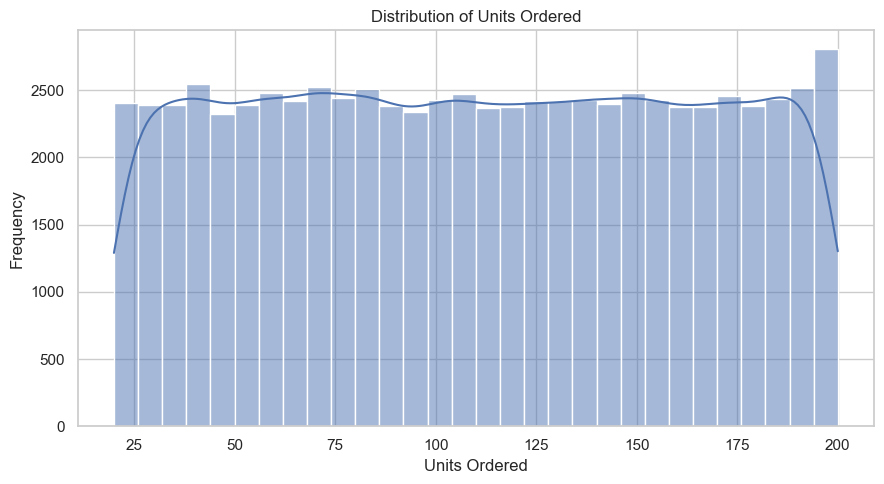

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(df["Units Ordered"], bins=30, kde=True)
plt.title("Distribution of Units Ordered")
plt.xlabel("Units Ordered")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


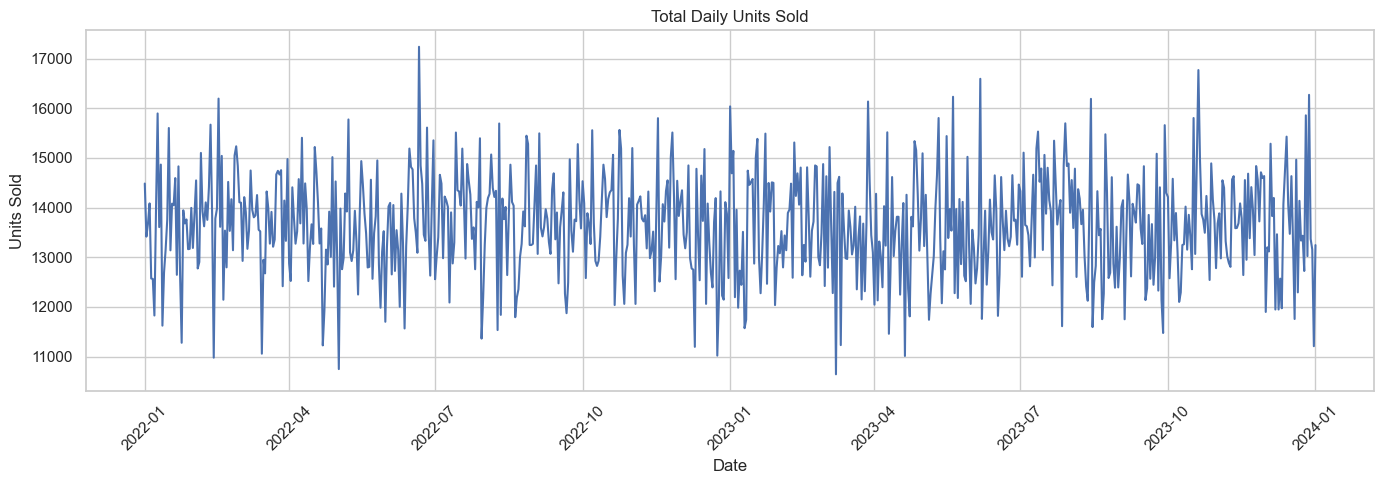

In [13]:
daily_sales = df.groupby("Date")["Units Sold"].sum()
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Total Daily Units Sold")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


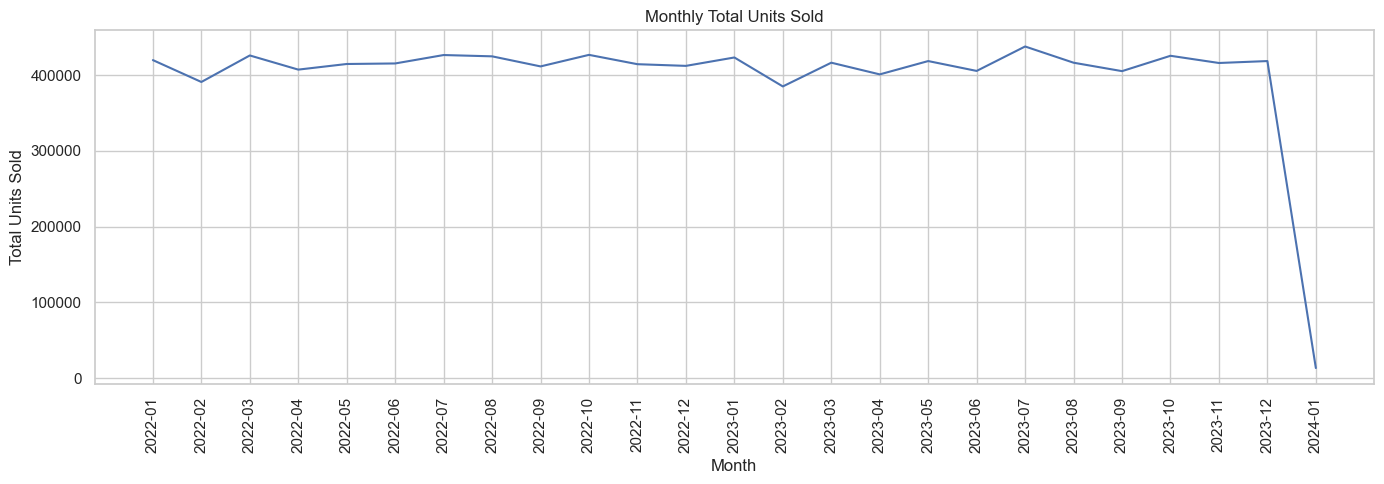

,Monthly Sales
count,25.000000
mean,399023.280000
std,81190.346535
min,13244.000000
25%,407380.000000
50%,416126.000000
75%,423408.000000
max,437919.000000


In [14]:
df["Month"] = df["Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Units Sold"].sum()
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values)
plt.title("Monthly Total Units Sold")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
display(monthly_sales.describe().to_frame("Monthly Sales"))


Inventory Level vs Units Sold correlation: 0.5900


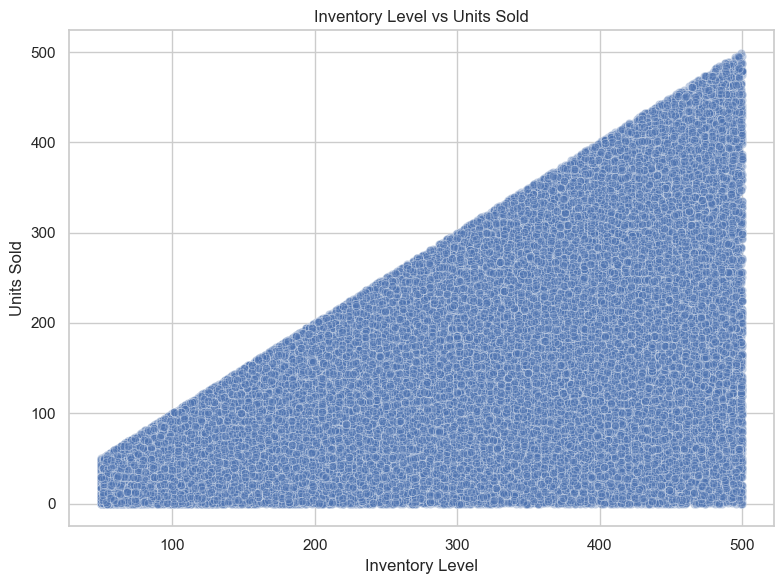

In [15]:
inventory_sales_corr = df["Inventory Level"].corr(df["Units Sold"])
print(f"Inventory Level vs Units Sold correlation: {inventory_sales_corr:.4f}")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Inventory Level", y="Units Sold", alpha=0.35)
plt.title("Inventory Level vs Units Sold")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()


Demand Forecast vs Units Sold correlation: 0.996853


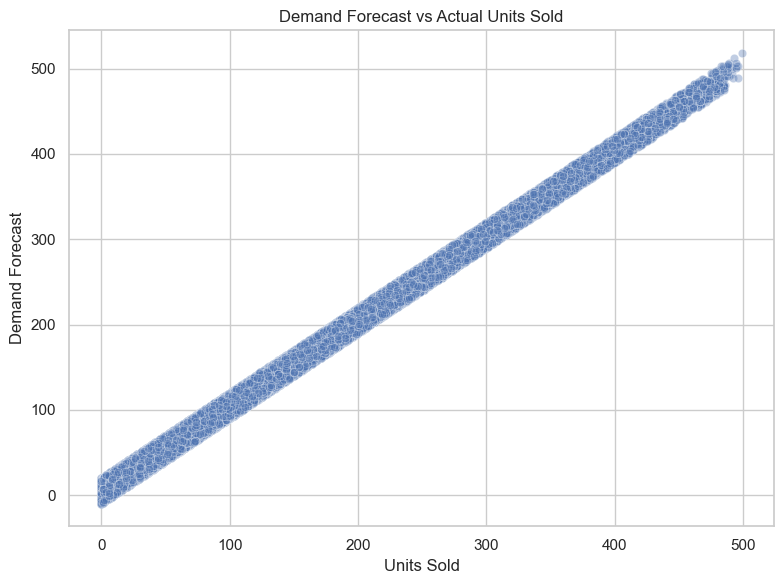

In [16]:
forecast_sales_corr = df["Demand Forecast"].corr(df["Units Sold"])
print(f"Demand Forecast vs Units Sold correlation: {forecast_sales_corr:.6f}")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Units Sold", y="Demand Forecast", alpha=0.35)
plt.title("Demand Forecast vs Actual Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Demand Forecast")
plt.tight_layout()
plt.show()


In [17]:
df["Forecast Difference"] = df["Demand Forecast"] - df["Units Sold"]
display(df["Forecast Difference"].describe().to_frame("Forecast Difference"))


,Forecast Difference
count,73100.000000
mean,5.029850
std,8.660766
min,-10.000000
25%,-2.470000
50%,4.990000
75%,12.510000
max,20.000000


Price vs Competitor Pricing correlation: 0.993900


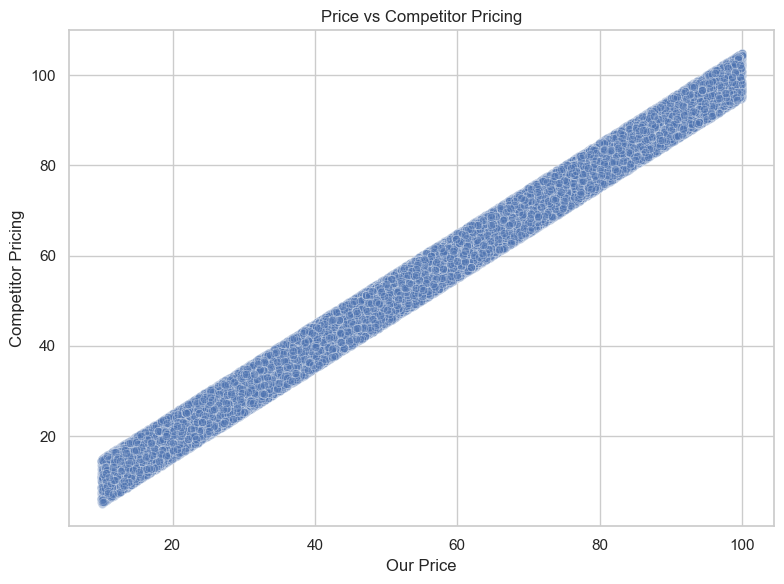

In [18]:
price_competitor_corr = df["Price"].corr(df["Competitor Pricing"])
print(f"Price vs Competitor Pricing correlation: {price_competitor_corr:.6f}")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Price", y="Competitor Pricing", alpha=0.35)
plt.title("Price vs Competitor Pricing")
plt.xlabel("Our Price")
plt.ylabel("Competitor Pricing")
plt.tight_layout()
plt.show()


In [19]:
inventory_thresholds = [50, 75, 100, 150]
threshold_results = []
for threshold in inventory_thresholds:
    count = (df["Inventory Level"] <= threshold).sum()
    threshold_results.append({
        "Threshold": threshold,
        "Records": count,
        "Percentage": count / len(df) * 100
    })
display(pd.DataFrame(threshold_results))


,Threshold,Records,Percentage
0,50,130,0.177839
1,75,4168,5.701778
2,100,8214,11.236662
3,150,16346,22.361149


In [20]:
sales_inventory_violation = (df["Units Sold"] > df["Inventory Level"]).sum()
print("Records where Units Sold > Inventory Level:", sales_inventory_violation)


Records where Units Sold > Inventory Level: 0


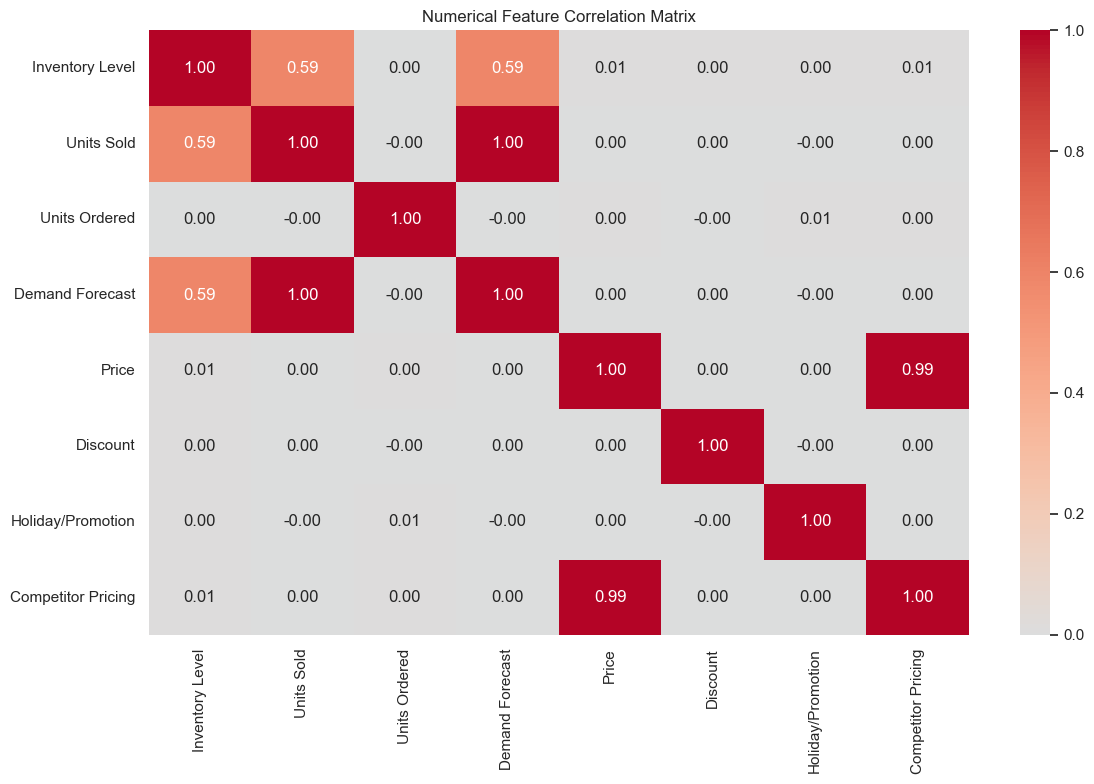

In [21]:
correlation_matrix = df[numerical_columns].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()


,Total Units Sold
Store ID,
S003,2022696
S005,2010176
S002,1987715
S004,1979245
S001,1975750


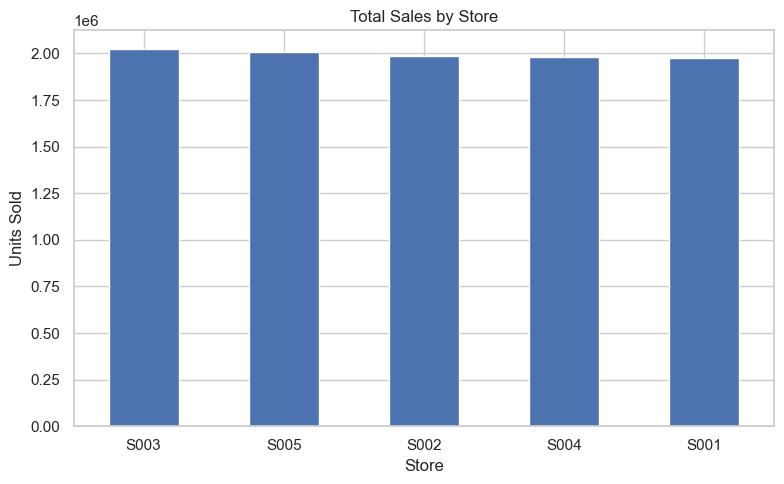

In [22]:
store_sales = df.groupby("Store ID")["Units Sold"].sum().sort_values(ascending=False)
display(store_sales.to_frame("Total Units Sold"))
plt.figure(figsize=(8, 5))
store_sales.plot(kind="bar")
plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Total Units Sold
Product ID,
P0016,508472
P0020,507708
P0014,507622
P0015,507283
P0005,503648
P0009,502086
P0013,500619
P0017,500510
P0011,499362


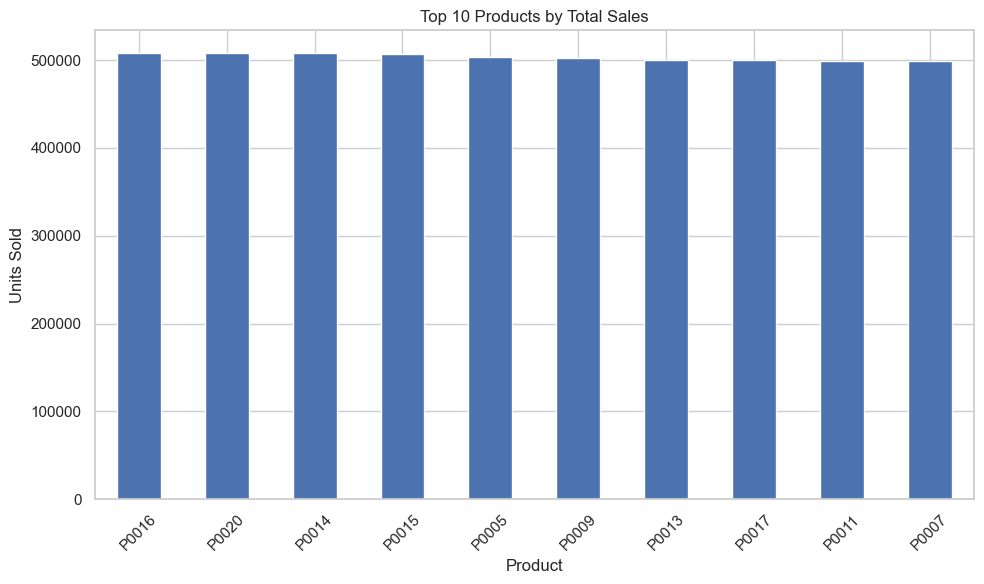

In [23]:
product_sales = df.groupby("Product ID")["Units Sold"].sum().sort_values(ascending=False)
display(product_sales.to_frame("Total Units Sold"))
plt.figure(figsize=(10, 6))
product_sales.head(10).plot(kind="bar")
plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Total Units Sold
Category,
Furniture,2025017
Groceries,2000482
Clothing,1999166
Toys,1990485
Electronics,1960432


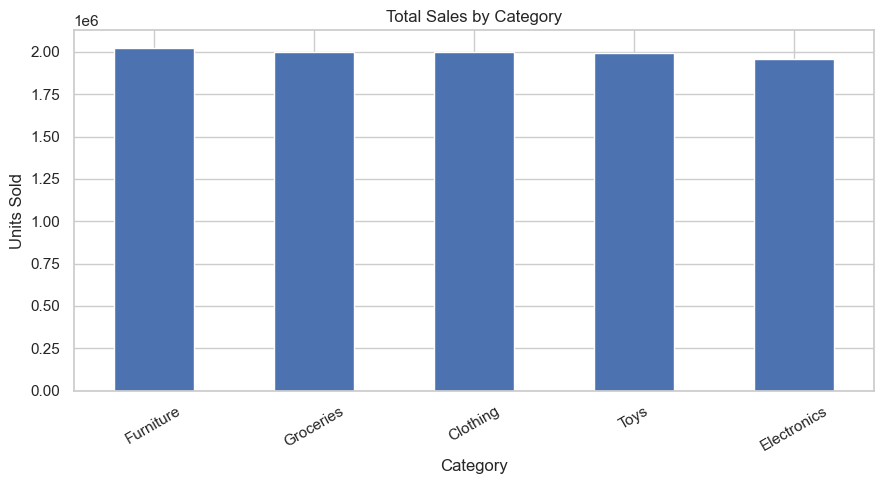

In [24]:
category_sales = df.groupby("Category")["Units Sold"].sum().sort_values(ascending=False)
display(category_sales.to_frame("Total Units Sold"))
plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [25]:
product_summary = df.groupby("Product ID").agg(
    total_sales=("Units Sold", "sum"),
    average_daily_sales=("Units Sold", "mean"),
    average_inventory=("Inventory Level", "mean"),
    average_price=("Price", "mean")
).sort_values("average_daily_sales", ascending=False)
display(product_summary)


,total_sales,average_daily_sales,average_inventory,average_price
Product ID,,,,
P0016,508472,139.116826,277.505062,54.832030
P0020,507708,138.907798,276.798358,55.524030
P0014,507622,138.884268,277.892202,55.761581
P0015,507283,138.791518,276.408208,54.770714
P0005,503648,137.796990,273.041860,55.023590
P0009,502086,137.369631,275.324761,55.156235
P0013,500619,136.968263,275.111354,55.062503
P0017,500510,136.938440,278.320930,54.646558
P0011,499362,136.624350,272.807661,56.433294
